In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from pyproj import Transformer
from scipy.interpolate import griddata

from em31_processing import read_em31

/opt/homebrew/Caskroom/miniconda/base/envs/gpgn-318/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [4]:
files = [
    "../../Data/EM_31_Data/molly2onyx.R31",
    "../../Data/EM_31_Data/mollyonyx.R31",
    "../../Data/EM_31_Data/onyxsmt.R31",
    "../../Data/EM_31_Data/onyxtms.R31"
]

datasets = {}

for file in files:

    data, gps = read_em31(file)

    if data.empty:
        print(f"{file}: No measurements found. Skipping.\n")
        continue

    datasets[file] = {
        "data": data,
        "gps": gps
    }

    print(f"{file}")
    print(f"Measurements: {len(data)}")
    print(f"GPS fixes: {len(gps)}")
    print(f"Segments: {data['segment'].nunique()}")
    print()

../../Data/EM_31_Data/molly2onyx.R31
Measurements: 1529
GPS fixes: 274
Segments: 5

../../Data/EM_31_Data/mollyonyx.R31
Measurements: 1466
GPS fixes: 0
Segments: 5

../../Data/EM_31_Data/onyxsmt.R31
Measurements: 119
GPS fixes: 21
Segments: 1

../../Data/EM_31_Data/onyxtms.R31: No measurements found. Skipping.



In [5]:
filename = "../../Data/EM_31_Data/molly2onyx.R31"

data = datasets[filename]["data"].copy()
gps = datasets[filename]["gps"].copy()

display(data.head())
display(data[["channel_1", "channel_2"]].describe())

,segment,channel_1,channel_2,counter
0,0,-88,208,2671312
1,0,-88,213,2671491
2,0,-88,220,2671670
3,0,-91,224,2671849
4,0,-92,228,2672028


,channel_1,channel_2
count,1529.000000,1529.000000
mean,-69.903205,258.367560
std,10.207907,44.018108
min,-92.000000,148.000000
25%,-76.000000,230.000000
50%,-72.000000,264.000000
75%,-64.000000,292.000000
max,-49.000000,416.000000


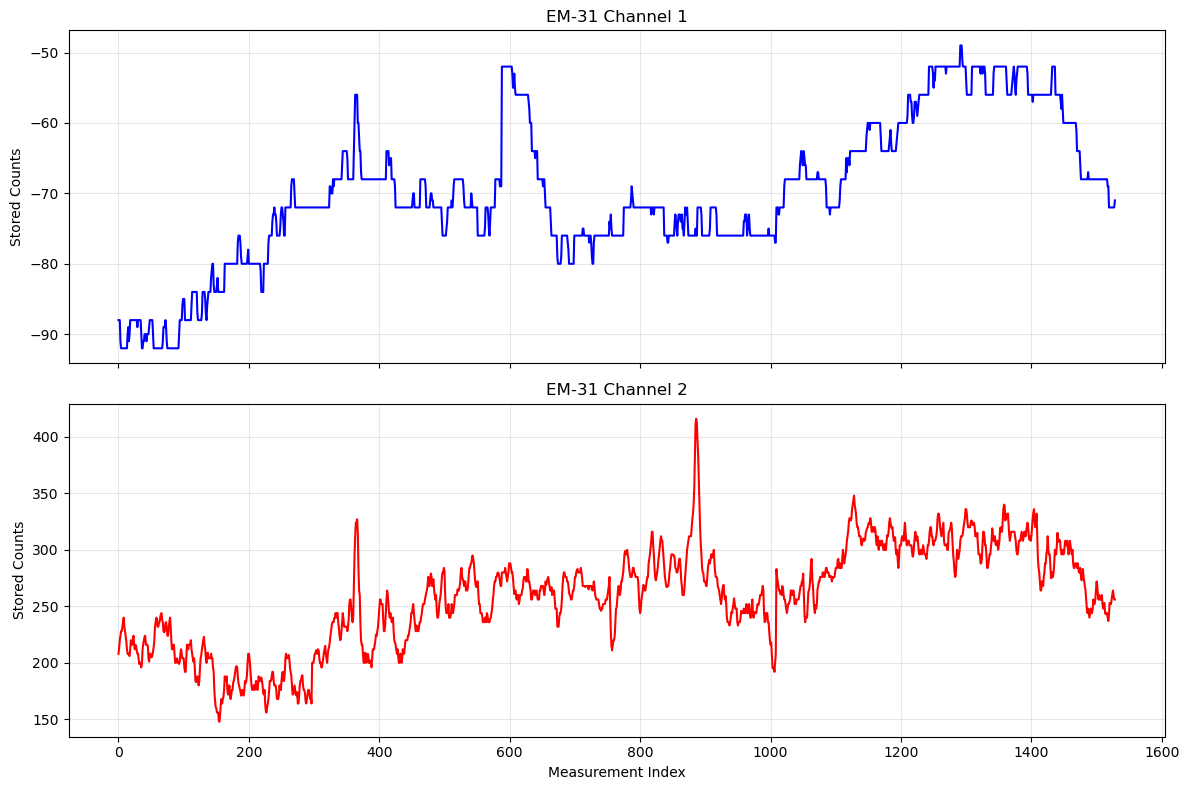

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(data.index, data["channel_1"], color="blue")
axes[1].plot(data.index, data["channel_2"], color="red")

axes[0].set_title("EM-31 Channel 1")
axes[0].set_ylabel("Stored Counts")

axes[1].set_title("EM-31 Channel 2")
axes[1].set_ylabel("Stored Counts")
axes[1].set_xlabel("Measurement Index")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

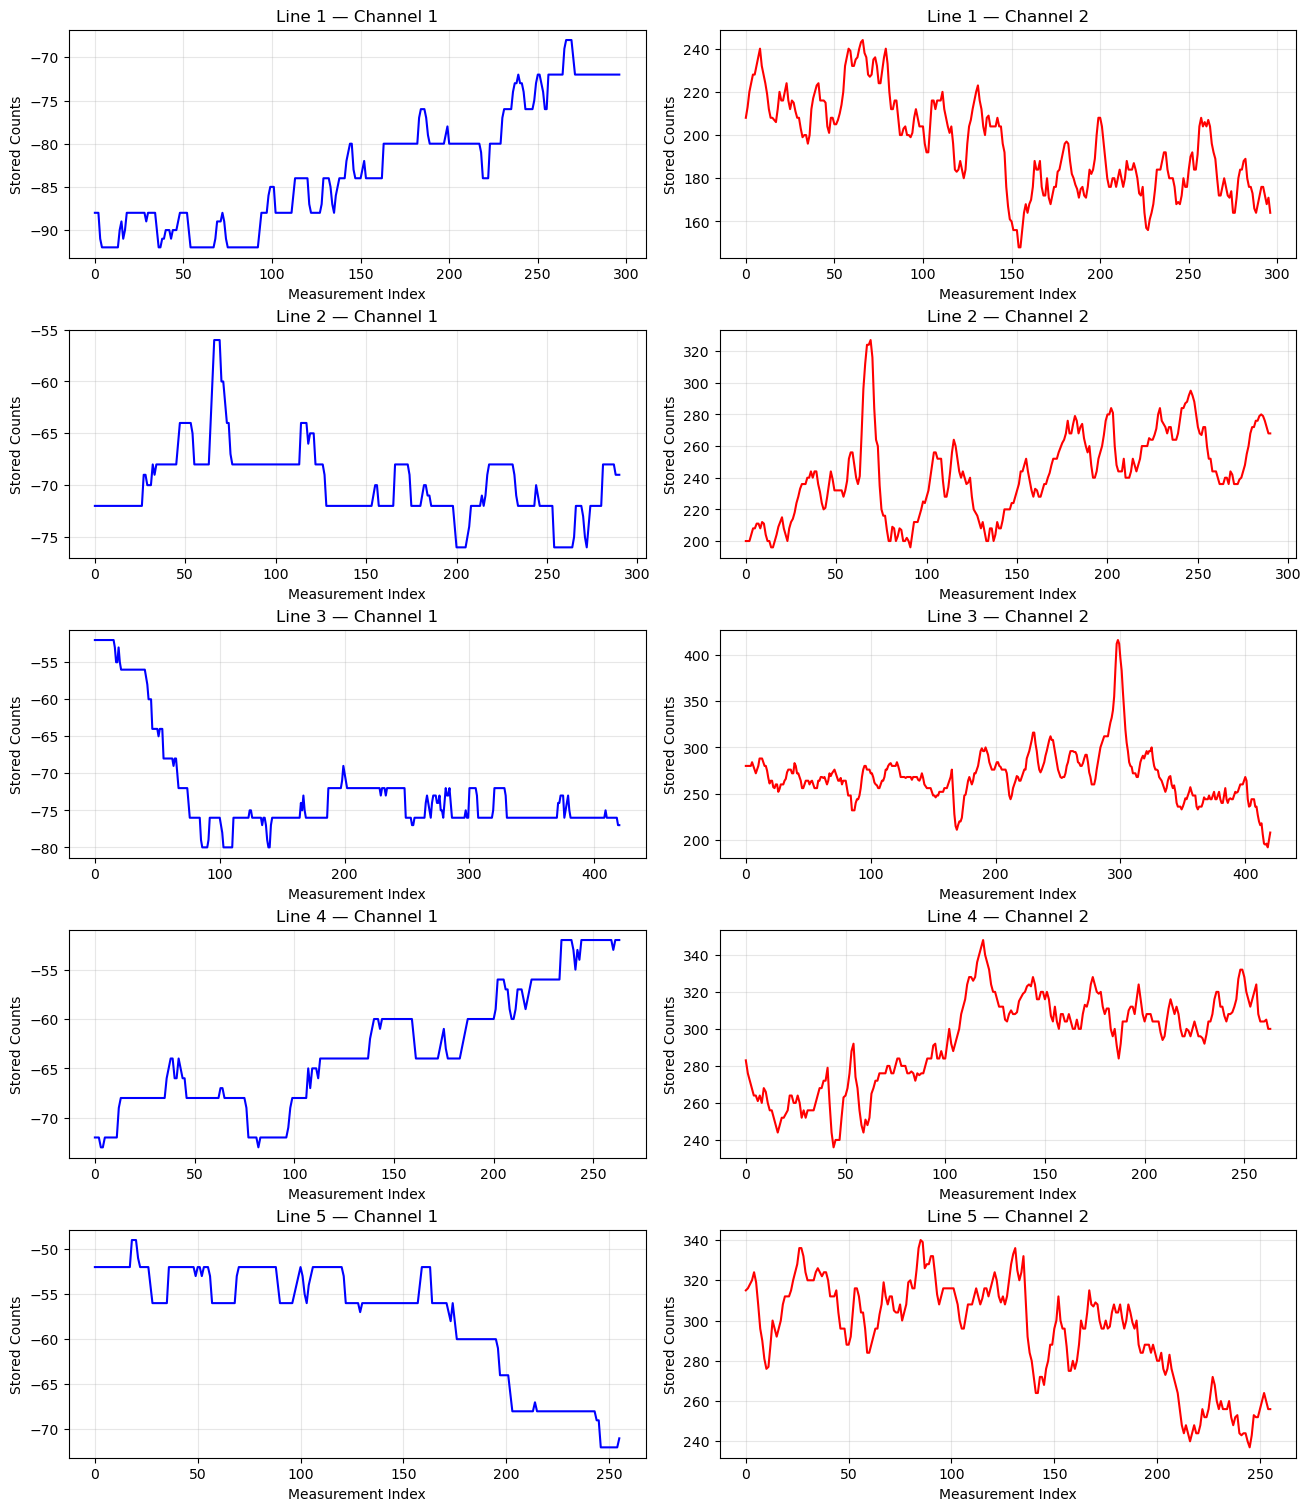

In [7]:
segments = sorted(data["segment"].unique())

fig, axes = plt.subplots(
    len(segments), 2,
    figsize=(13, 3 * len(segments)),
    squeeze=False,
    constrained_layout=True
)

for i, seg in enumerate(segments):

    line = data[data["segment"] == seg]
    x = np.arange(len(line))

    axes[i, 0].plot(x, line["channel_1"], color="blue")
    axes[i, 1].plot(x, line["channel_2"], color="red")

    axes[i, 0].set_title(f"Line {seg+1} — Channel 1")
    axes[i, 1].set_title(f"Line {seg+1} — Channel 2")

    for ax in axes[i]:
        ax.set_xlabel("Measurement Index")
        ax.set_ylabel("Stored Counts")
        ax.grid(alpha=0.3)

plt.show()

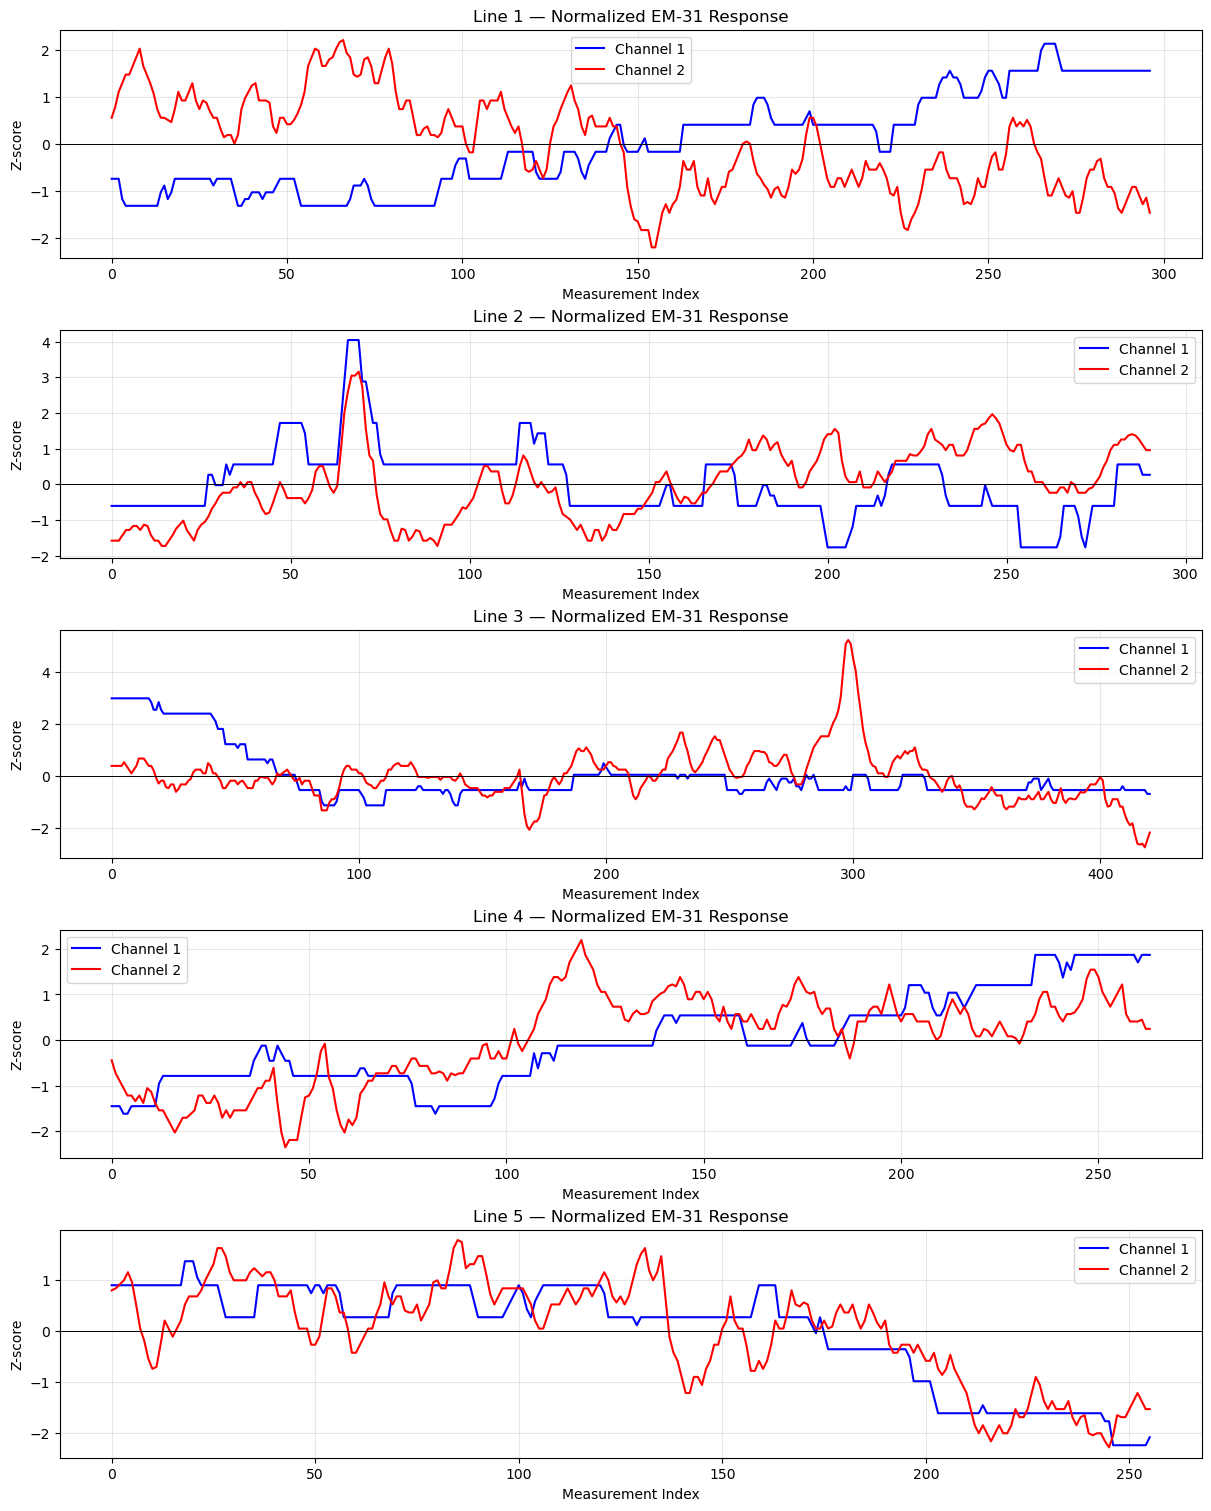

In [8]:
fig, axes = plt.subplots(
    len(segments), 1,
    figsize=(12, 3 * len(segments)),
    constrained_layout=True
)

for i, seg in enumerate(segments):

    line = data[data["segment"] == seg]
    x = np.arange(len(line))

    ch1 = line["channel_1"]
    ch2 = line["channel_2"]

    ch1_norm = (ch1 - ch1.mean()) / ch1.std()
    ch2_norm = (ch2 - ch2.mean()) / ch2.std()

    axes[i].plot(x, ch1_norm, label="Channel 1", color="blue")
    axes[i].plot(x, ch2_norm, label="Channel 2", color="red")

    axes[i].axhline(0, color="black", linewidth=0.7)

    axes[i].set_title(f"Line {seg+1} — Normalized EM-31 Response")
    axes[i].set_ylabel("Z-score")
    axes[i].set_xlabel("Measurement Index")
    axes[i].legend()
    axes[i].grid(alpha=0.3)

plt.show()

In [11]:
from pyproj import Proj

# Define UTM Zone 13N directly
utm = Proj(
    proj="utm",
    zone=13,
    datum="WGS84",
    units="m"
)

# Convert GPS coordinates
east, north = utm(
    gps["longitude"].to_numpy(),
    gps["latitude"].to_numpy()
)

print("Easting:", east[:5])
print("Northing:", north[:5])

Easting: [344408.41220987 344408.36463847 344408.38291966 344408.63950052
 344408.72547471]
Northing: [4482532.78883474 4482532.43166708 4482531.82936024 4482531.24745352
 4482530.6515123 ]


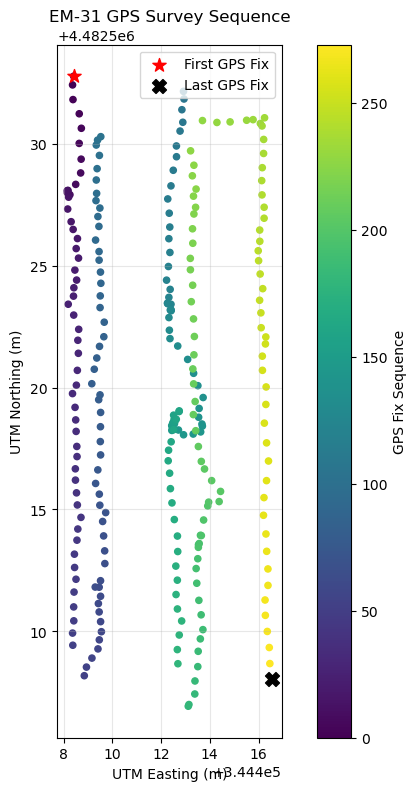

In [12]:
fig, ax = plt.subplots(figsize=(9, 9))

sc = ax.scatter(
    east, north,
    c=np.arange(len(gps)),
    cmap="viridis",
    s=20
)

ax.scatter(
    east[0], north[0],
    color="red",
    s=100,
    marker="*",
    label="First GPS Fix"
)

ax.scatter(
    east[-1], north[-1],
    color="black",
    s=100,
    marker="X",
    label="Last GPS Fix"
)

ax.set_title("EM-31 GPS Survey Sequence")
ax.set_xlabel("UTM Easting (m)")
ax.set_ylabel("UTM Northing (m)")
ax.set_aspect("equal")
ax.legend()
ax.grid(alpha=0.3)

plt.colorbar(sc, ax=ax, label="GPS Fix Sequence")
plt.show()